# Predicting CI Build Failures in WSO2 and Ballerina Repositories

WSO2 is a Sri Lankan software company, and most of its products and the Ballerina language are built in the open on GitHub. Every pull request triggers a GitHub Actions build that compiles the code and runs the tests. Many of these builds fail, and each failure costs runner time and developer waiting time.

**Goal:** predict, at the moment a PR build starts, whether it will fail. This is a binary classification problem.

A useful model lets a team:
- warn developers early when a change looks risky,
- run risky builds first or with extra checks,
- spot repositories or patterns that keep breaking.

The data is real, public and local to Sri Lanka's software industry.

## 1. Setup

In [2]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, f1_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline

from src.features import (BINARY, CATEGORICAL, FEATURES, NUMERIC, TARGET,
                          add_history_features, add_static_features, load_raw, time_split)
from src.train import best_threshold, candidates, preprocessor, scores

SEED = 42
FIG = Path("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
ORANGE, GREEN, GREY = "#F26722", "#2FB67C", "#8A8F9C"

## 2. Data source and collection

The data comes from the GitHub REST API, collected with `src/collect.py` and a read-only token.

| Step | Details |
|---|---|
| Repositories | 3 WSO2 products (`carbon-identity-framework`, `identity-apps`, `carbon-apimgt`) and 3 Ballerina modules (`http`, `grpc`, `kafka`) |
| Workflow | Only each repo's main PR build workflow. Scheduled security scans have no code change behind them, so they are excluded. |
| Runs | Completed runs with conclusion `success` or `failure`, up to 700 most recent per repo |
| Per run | Event, fork or not, run attempt, timestamps, actor (hashed) |
| Per commit | Lines added and deleted, files changed, file types touched, commit message size |
| Per PR | Author association (member, contributor), PR creation time, when GitHub links the commit to a PR |

**Ethics and privacy.** All of this is public metadata; no source code or logs are stored. Usernames and branch names are replaced with salted SHA-256 hashes before saving. The token lives in `.env`, which is never committed.

I selected repos by checking their Actions history first. `product-micro-integrator` was dropped because 89% of its recent runs failed, which points to a suite that is broken all the time rather than individual changes that fail.

In [3]:
raw = load_raw("data/raw")
print(raw.shape)
raw[["repo", "event", "run_attempt", "is_fork", "is_bot", "additions", "deletions",
     "files_changed", "pr_author_association", "created_at", "conclusion"]].head()

(2948, 41)


,repo,event,run_attempt,is_fork,is_bot,additions,deletions,files_changed,pr_author_association,created_at,conclusion
0,ballerina-platform/module-ballerina-grpc,pull_request,1,0,0,3.0,0.0,1.0,MEMBER,2026-10-22T05:33:03Z,success
1,ballerina-platform/module-ballerina-grpc,pull_request,1,0,0,0.0,2.0,1.0,MEMBER,2026-10-19T12:05:10Z,success
2,ballerina-platform/module-ballerina-grpc,pull_request,1,0,0,8.0,0.0,1.0,MEMBER,2026-10-19T11:26:56Z,success
3,ballerina-platform/module-ballerina-grpc,pull_request,1,0,0,2.0,0.0,1.0,MEMBER,2026-10-19T10:25:52Z,success
4,ballerina-platform/module-ballerina-grpc,pull_request,1,0,0,5.0,1.0,1.0,CONTRIBUTOR,2026-10-16T09:01:10Z,success


In [4]:
summary = raw.groupby("repo").agg(
    runs=("run_id", "size"),
    failure_rate=("conclusion", lambda s: (s == "failure").mean()),
    first_run=("created_at", "min"),
    last_run=("created_at", "max"),
    pull_requests=("pr_key", "nunique"),
    authors=("actor_hash", "nunique"),
).round(3)
summary["first_run"] = summary["first_run"].str[:10]
summary["last_run"] = summary["last_run"].str[:10]
summary

,runs,failure_rate,first_run,last_run,pull_requests,authors
repo,,,,,,
ballerina-platform/module-ballerina-grpc,172,0.343,2025-09-08,2026-10-22,49,13
ballerina-platform/module-ballerina-http,574,0.408,2025-09-08,2026-10-22,172,29
ballerina-platform/module-ballerinax-kafka,102,0.422,2025-09-08,2026-10-22,26,10
wso2/carbon-apimgt,700,0.296,2026-06-23,2026-10-22,135,55
wso2/carbon-identity-framework,700,0.249,2026-06-16,2026-10-23,198,46
wso2/identity-apps,700,0.264,2026-06-02,2026-10-22,238,56


## 3. Data quality and cleaning

In [5]:
print("duplicate run ids:", raw["run_id"].duplicated().sum())
print("conclusions:", raw["conclusion"].value_counts().to_dict())
missing = raw.isna().mean().sort_values(ascending=False)
missing[missing > 0].round(3).to_frame("missing_share")

duplicate run ids: 0
conclusions: {'success': 2046, 'failure': 902}


,missing_share
pr_is_draft,0.493
pr_base_ref,0.493
pr_created_at,0.493
pr_author_association,0.493
pr_number,0.493
n_dep_files,0.065
files_added,0.065
files_removed,0.065
n_code_files,0.065
n_test_files,0.065


- There are no duplicate runs, and only `success` and `failure` were kept, so cancelled and skipped runs are already gone.
- **PR details are missing for about half of the runs (49%).** WSO2 developers open PRs from personal forks, and for many fork commits GitHub does not return the linked PR. I don't drop these rows; author association becomes `UNKNOWN`, and the imputer adds a "missing" indicator for PR age. Runs are still grouped into PRs with `pr_key`, a hash of fork and branch, which is always available.
- Commit details are missing for 6.5% of runs, where the commit is no longer reachable through the API (for example, a force-pushed fork branch). Those rows keep zeros for the commit counts.

In [6]:
raw[["additions", "deletions", "files_changed"]].describe(percentiles=[.5, .9, .99]).round(1)

,additions,deletions,files_changed
count,2755.0,2755.0,2755.0
mean,695.5,109.5,16.7
std,8349.9,1168.1,44.4
min,0.0,0.0,0.0
50%,25.0,5.0,2.0
90%,689.0,126.0,51.0
99%,9750.2,1657.0,300.0
max,316486.0,54073.0,300.0


Change size is heavily skewed: the median change touches a few files, while the top 1% touch hundreds (mass renames, generated files, version bumps). These are real events rather than errors, so I keep them. The model uses `log_churn = log(1 + added + deleted)`, and tree models are not affected by the scale.

## 4. Exploratory data analysis

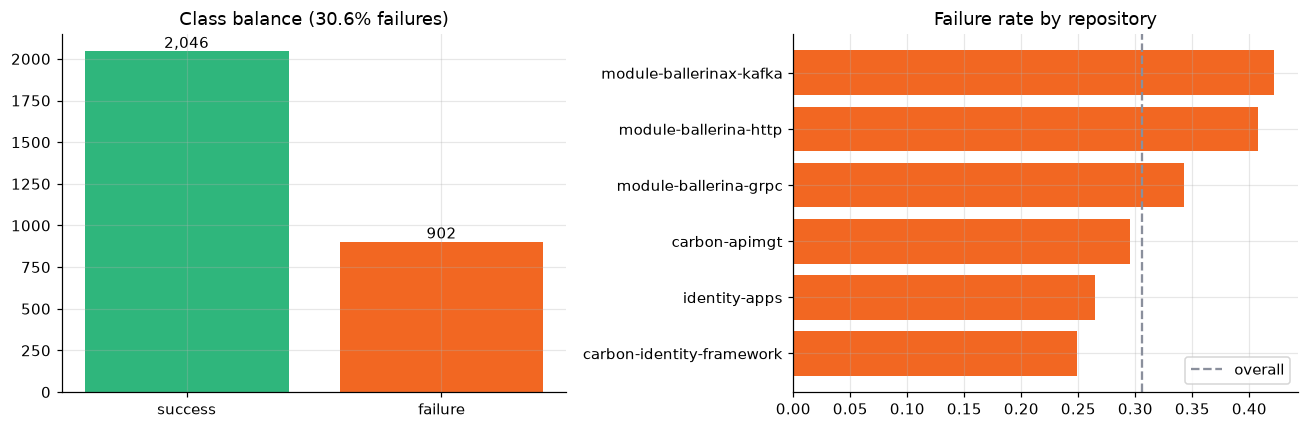

In [7]:
df = add_static_features(raw)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts = df["failed"].value_counts().rename({0: "success", 1: "failure"})
ax[0].bar(counts.index, counts.values, color=[GREEN, ORANGE])
ax[0].set_title(f"Class balance ({df['failed'].mean():.1%} failures)")
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 20, f"{v:,}", ha="center")

rate = df.groupby("repo")["failed"].mean().sort_values()
ax[1].barh([r.split("/")[-1] for r in rate.index], rate.values, color=ORANGE)
ax[1].axvline(df["failed"].mean(), color=GREY, ls="--", label="overall")
ax[1].set_title("Failure rate by repository")
ax[1].legend()
plt.tight_layout()
plt.savefig(FIG / "eda_class_balance.png", bbox_inches="tight")
plt.show()

About **31% of builds fail**, so the classes are imbalanced but not extreme. Accuracy alone would be misleading: always predicting "success" already scores 69%. I report **PR-AUC, F1, precision and recall**, and use class weights.

The Ballerina modules fail more often (34–42%) than the WSO2 products (25–30%), so the repository has to be a feature.

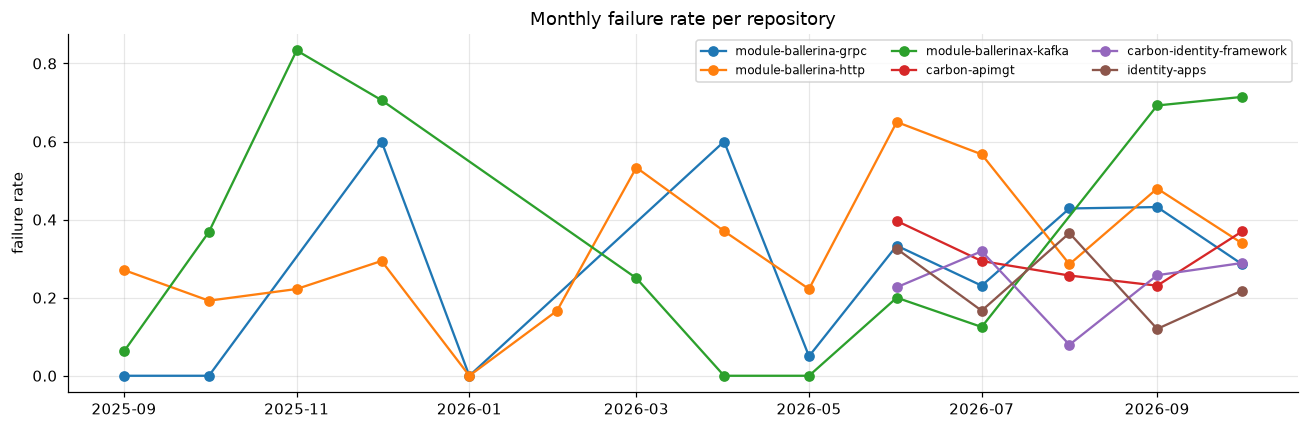

In [8]:
monthly = df.set_index("created_at").groupby([pd.Grouper(freq="MS"), "repo"])["failed"].agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(12, 4))
for repo, part in monthly.groupby(level="repo"):
    part = part.droplevel("repo")
    ax.plot(part.index, part["mean"], marker="o", label=repo.split("/")[-1])
ax.set_title("Monthly failure rate per repository")
ax.set_ylabel("failure rate")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "eda_monthly.png", bbox_inches="tight")
plt.show()

Failure rates move month to month, and the WSO2 repos only cover June–October 2026 because of the 700-run cap. This drift is a strong reason to use a **time-based split**: a random split would mix future months into training.

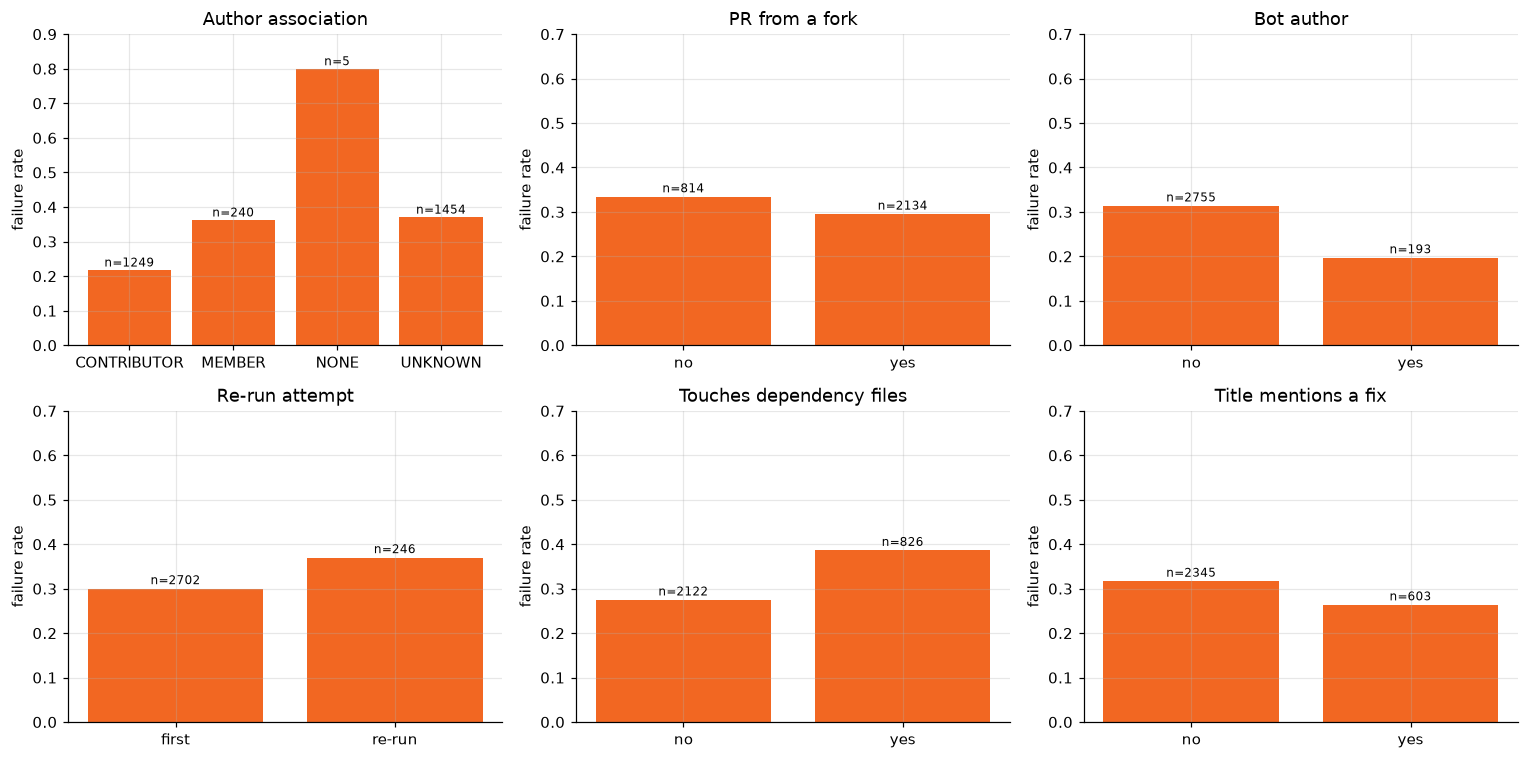

In [9]:
def rate_plot(ax, col, title, labels=None):
    g = df.groupby(col)["failed"].agg(["mean", "size"])
    names = [labels.get(i, i) if labels else str(i) for i in g.index]
    ax.bar(names, g["mean"], color=ORANGE)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.01, f"n={n}", ha="center", fontsize=8)
    ax.set_title(title)
    ax.set_ylim(0, max(0.7, g["mean"].max() + 0.1))

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
rate_plot(ax[0, 0], "author_association", "Author association")
rate_plot(ax[0, 1], "is_fork", "PR from a fork", {0: "no", 1: "yes"})
rate_plot(ax[0, 2], "is_bot", "Bot author", {0: "no", 1: "yes"})
rate_plot(ax[1, 0], "is_rerun", "Re-run attempt", {0: "first", 1: "re-run"})
rate_plot(ax[1, 1], "touches_deps", "Touches dependency files", {0: "no", 1: "yes"})
rate_plot(ax[1, 2], "title_fix", "Title mentions a fix", {0: "no", 1: "yes"})
for a in ax.flat:
    a.set_ylabel("failure rate")
plt.tight_layout()
plt.savefig(FIG / "eda_context.png", bbox_inches="tight")
plt.show()

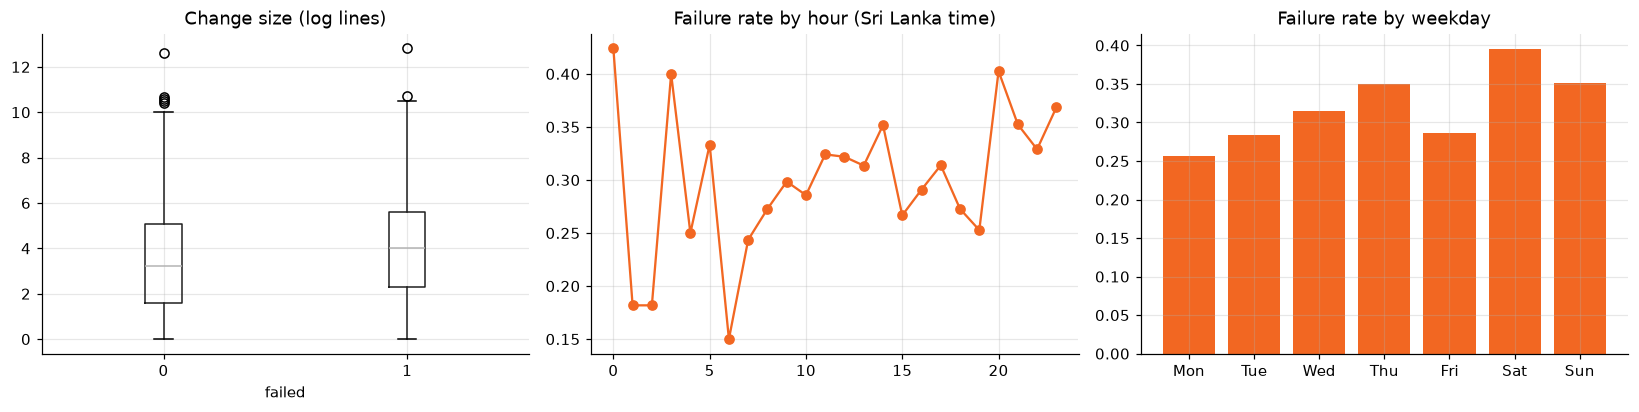

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.boxplot(column="log_churn", by="failed", ax=ax[0])
ax[0].set_title("Change size (log lines)")
ax[0].set_xlabel("failed")
hours = df.groupby("hour")["failed"].mean()
ax[1].plot(hours.index, hours.values, marker="o", color=ORANGE)
ax[1].set_title("Failure rate by hour (Sri Lanka time)")
days = df.groupby("weekday")["failed"].mean()
ax[2].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], days.values, color=ORANGE)
ax[2].set_title("Failure rate by weekday")
plt.suptitle("")
plt.tight_layout()
plt.savefig(FIG / "eda_size_time.png", bbox_inches="tight")
plt.show()

What the context and change plots show:
- Failed builds are slightly larger changes on average, but the distributions overlap heavily. **Size alone cannot separate the classes.**
- Bot PRs (Dependabot, renovate) and dependency changes behave differently from human code changes.
- Time of day and weekday matter only a little. Evening and weekend runs are fewer and noisier.

## 5. Feature engineering without leakage

The model must only use information that exists **when the build starts**. This rules out run duration, the run's final update time, and the PR's final size, since later commits change it.

History features are the most useful, and also the easiest place to leak. `src/features.py` builds them in one pass over each repository in time order, and **only counts runs that had already finished before the current run was created**. A run that is still in progress does not count.

| Group | Features |
|---|---|
| Change | lines added and deleted, log churn, files changed, top-level folders touched, files added and removed, code/test/config/doc/dependency/CI file counts, test file ratio, docs-only, commit message length |
| Context | repository, event, fork, bot, re-run, author association, hour, weekday, weekend, PR age, commit age, title length and keywords (fix, revert, test, dependency) |
| History | repo failure rate of the last 20 finished runs, current repo failure streak, previous repo run failed, author's earlier runs and smoothed failure rate, earlier runs and failures on the same PR, last run on the PR failed, minutes since the previous run on the PR, earlier runs of the same commit |

The author failure rate is smoothed toward the repository's average, `(failures + 5 * repo_rate) / (runs + 5)`, so a new author with one failed run doesn't get a rate of 100%.

In [11]:
df = add_history_features(df)
print(df.shape, "features:", len(FEATURES))
df[["created_at", "repo", "pr_prior_runs", "pr_prev_failed", "author_prior_runs",
    "author_fail_rate", "repo_fail_rate_20", "failed"]].tail()

(2948, 71) features: 47


,created_at,repo,pr_prior_runs,pr_prev_failed,author_prior_runs,author_fail_rate,repo_fail_rate_20,failed
2943,2026-10-22 15:40:24+00:00,wso2/carbon-identity-framework,8.0,1.0,58.0,0.511705,0.25,1
2944,2026-10-22 16:58:52+00:00,wso2/carbon-identity-framework,9.0,1.0,59.0,0.519419,0.30,1
2945,2026-10-22 18:29:35+00:00,wso2/carbon-identity-framework,10.0,1.0,60.0,0.526895,0.35,0
2946,2026-10-23 03:47:57+00:00,wso2/carbon-identity-framework,0.0,0.0,47.0,0.158585,0.35,0
2947,2026-10-23 04:06:16+00:00,wso2/carbon-identity-framework,1.0,0.0,48.0,0.155559,0.35,0


A brute-force check of the history features: for 300 random runs I recount earlier finished runs on the same PR directly and compare.

In [12]:
rng = np.random.default_rng(SEED)
mismatch = 0
for i in rng.choice(len(df), 300, replace=False):
    r = df.iloc[i]
    earlier = df[(df.repo == r.repo) & (df.pr_key == r.pr_key) & (df.updated_at < r.created_at)]
    mismatch += int(len(earlier) != r.pr_prior_runs or earlier.failed.sum() != r.pr_prior_failures)
print("mismatches:", mismatch)

mismatches: 0


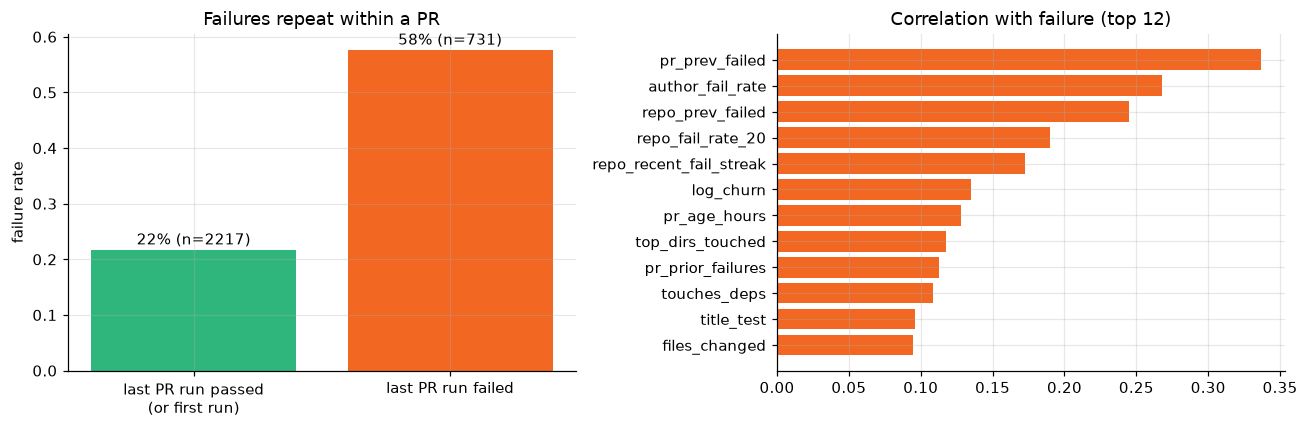

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
g = df.groupby("pr_prev_failed")["failed"].agg(["mean", "size"])
ax[0].bar(["last PR run passed\n(or first run)", "last PR run failed"], g["mean"], color=[GREEN, ORANGE])
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    ax[0].text(i, m + 0.01, f"{m:.0%} (n={n})", ha="center")
ax[0].set_title("Failures repeat within a PR")
ax[0].set_ylabel("failure rate")

corr = df[NUMERIC + BINARY].corrwith(df[TARGET]).dropna().sort_values(key=np.abs, ascending=False).head(12)
ax[1].barh(corr.index[::-1], corr.values[::-1], color=[ORANGE if v > 0 else GREEN for v in corr.values[::-1]])
ax[1].set_title("Correlation with failure (top 12)")
plt.tight_layout()
plt.savefig(FIG / "eda_history.png", bbox_inches="tight")
plt.show()

The strongest single signal is history: **when the last run on a PR failed, the next run fails 58% of the time, against 22% otherwise.** A developer pushing a fix often doesn't fix everything at once. The author's past failure rate and the repo's recent rate come next. No single feature correlates above about 0.35, so the model has to combine many weak signals.

## 6. Why the split must follow time

To show how much leakage would inflate the results, I compare three setups using the same LightGBM settings:
1. a random stratified 5-fold CV with the normal features,
2. the same with run duration added, which is only known after the run,
3. a time-ordered 5-fold CV with the normal features, which is the honest setup.

In [14]:
from lightgbm import LGBMClassifier

data = df.sort_values("created_at").reset_index(drop=True)
data["duration_min"] = (pd.to_datetime(data["updated_at"], utc=True) - pd.to_datetime(data["run_started_at"], utc=True)).dt.total_seconds() / 60

def lgbm_pipe(cols_num):
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import OneHotEncoder
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), cols_num),
        ("bin", SimpleImputer(strategy="constant", fill_value=0), BINARY),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)])
    return Pipeline([("prep", prep), ("model", LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15,
                                                               class_weight="balanced", verbose=-1, random_state=SEED))])

setups = {
    "random CV": (NUMERIC, StratifiedKFold(5, shuffle=True, random_state=SEED)),
    "random CV + duration (leak)": (NUMERIC + ["duration_min"], StratifiedKFold(5, shuffle=True, random_state=SEED)),
    "time-ordered CV": (NUMERIC, TimeSeriesSplit(5)),
}
rows = []
for name, (num, cv) in setups.items():
    X = data[num + BINARY + CATEGORICAL]
    rows.append({"setup": name,
                 "ROC-AUC": cross_val_score(lgbm_pipe(num), X, data[TARGET], cv=cv, scoring="roc_auc").mean(),
                 "PR-AUC": cross_val_score(lgbm_pipe(num), X, data[TARGET], cv=cv, scoring="average_precision").mean()})
leak_table = pd.DataFrame(rows).round(3)
leak_table

,setup,ROC-AUC,PR-AUC
0,random CV,0.793,0.640
1,random CV + duration (leak),0.903,0.862
2,time-ordered CV,0.719,0.528


Adding duration produces a much better-looking model, but it would be useless in practice: duration is only known once the build has finished. A random split also scores higher than the time-ordered one, because it lets the model learn from runs that happen after the ones it is tested on. **The time-ordered numbers are the realistic ones, and every result below uses them.**

## 7. Train, validation and test split

Runs are sorted by creation time:
- the oldest 70% are for **training**,
- the next 15% for **validation**, used for model choice and the decision threshold,
- the newest 15% are a **test** set that is used only once at the end.

Hyperparameter tuning uses `TimeSeriesSplit` inside the training set.

In [15]:
train, val, test = time_split(df, 0.70, 0.15)
split_info = pd.DataFrame({
    "rows": [len(train), len(val), len(test)],
    "failure_rate": [train.failed.mean(), val.failed.mean(), test.failed.mean()],
    "from": [train.created_at.min(), val.created_at.min(), test.created_at.min()],
    "to": [train.created_at.max(), val.created_at.max(), test.created_at.max()],
}, index=["train", "validation", "test"])
split_info["from"] = split_info["from"].dt.strftime("%Y-%m-%d")
split_info["to"] = split_info["to"].dt.strftime("%Y-%m-%d")
split_info.round(3)

,rows,failure_rate,from,to
train,2063,0.302,2025-09-08,2026-09-07
validation,442,0.312,2026-09-07,2026-09-30
test,443,0.316,2026-09-30,2026-10-23


In [16]:
Xtr, ytr = train[FEATURES], train[TARGET]
Xva, yva = val[FEATURES], val[TARGET]
Xte, yte = test[FEATURES], test[TARGET]
pos_weight = (1 - ytr.mean()) / ytr.mean()
print(f"positive class weight for XGBoost: {pos_weight:.2f}")

positive class weight for XGBoost: 2.31


## 8. Preprocessing and models

The preprocessing is one `ColumnTransformer` inside the model pipeline, so it is fitted only on training folds:
- numeric features: median imputation plus a missing-value indicator; scaling for logistic regression only,
- binary features: missing values set to 0,
- categorical features (repo, event, author association): one-hot encoding, with rare levels grouped and unseen levels ignored.

| Model | Why |
|---|---|
| Prior baseline | Always predicts the training failure rate; the floor to beat |
| Logistic regression | Simple, interpretable linear baseline with class weights |
| Random forest | Captures non-linear effects and interactions, robust to outliers |
| LightGBM | Gradient boosting, strong on tabular data with mixed features |
| XGBoost | A second boosting implementation to confirm the result |

Each model is tuned with `RandomizedSearchCV` (25 settings, 4 time-ordered folds, scored on PR-AUC). Imbalance is handled with class weights, or `scale_pos_weight` for XGBoost, rather than SMOTE, because synthetic samples would break the time order of the history features.

In [17]:
cv = TimeSeriesSplit(n_splits=4)
results, fitted = [], {}

dummy = DummyClassifier(strategy="prior").fit(Xtr, ytr)
results.append({"model": "baseline_prior", "cv_pr_auc": np.nan, "train_pr_auc": average_precision_score(ytr, dummy.predict_proba(Xtr)[:, 1]),
                "threshold": 0.5, **{f"val_{k}": v for k, v in scores(yva, dummy.predict_proba(Xva)[:, 1], 0.5).items()}})

for name, (est, scale, grid) in candidates(pos_weight, SEED).items():
    pipe = Pipeline([("prep", preprocessor(scale)), ("model", est)])
    search = RandomizedSearchCV(pipe, grid, n_iter=25, scoring="average_precision", cv=cv, random_state=SEED, n_jobs=-1)
    search.fit(Xtr, ytr)
    pv = search.predict_proba(Xva)[:, 1]
    t = best_threshold(yva, pv)
    fitted[name] = (search.best_estimator_, t, search.best_params_)
    results.append({"model": name, "cv_pr_auc": search.best_score_,
                    "train_pr_auc": average_precision_score(ytr, search.predict_proba(Xtr)[:, 1]),
                    "threshold": t, **{f"val_{k}": v for k, v in scores(yva, pv, t).items()}})

val_table = pd.DataFrame(results).set_index("model").round(3)
val_table

,cv_pr_auc,train_pr_auc,threshold,val_roc_auc,val_pr_auc,val_f1,val_precision,val_recall
model,,,,,,,,
baseline_prior,NaN,0.302,0.50,0.500,0.312,0.000,0.000,0.000
logistic_regression,0.486,0.617,0.37,0.769,0.583,0.606,0.472,0.848
random_forest,0.564,0.708,0.32,0.741,0.563,0.566,0.411,0.906
lightgbm,0.545,0.804,0.40,0.784,0.638,0.605,0.515,0.732
xgboost,0.541,0.816,0.45,0.773,0.617,0.601,0.534,0.688


In [18]:
for name, (_, _, params) in fitted.items():
    print(name, {k.replace("model__", ""): v for k, v in params.items()})

logistic_regression {'C': np.float64(0.029763514416313176)}
random_forest {'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 4}
lightgbm {'subsample_freq': 1, 'subsample': 0.7, 'reg_lambda': 5, 'num_leaves': 15, 'n_estimators': 400, 'min_child_samples': 20, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
xgboost {'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.8}


How to read the validation table:
- All four models clearly beat the baseline: PR-AUC 0.56–0.64 against 0.31.
- **LightGBM has the best validation PR-AUC**, so it is the selected model. XGBoost is close behind, and the two boosting models agree.
- Every model scores higher on the training period than on validation. Logistic regression has the smallest gap (0.62 vs 0.58), the boosting models the largest (about 0.80 vs 0.63). Tuning already chose a low learning rate (0.01), row subsampling and L2 regularisation to limit this, and the boosting models still give the best validation score, so the extra fit is not hurting them on unseen months.
- Cross-validation scores are a little lower than validation, which is normal: the early folds train on very little history.

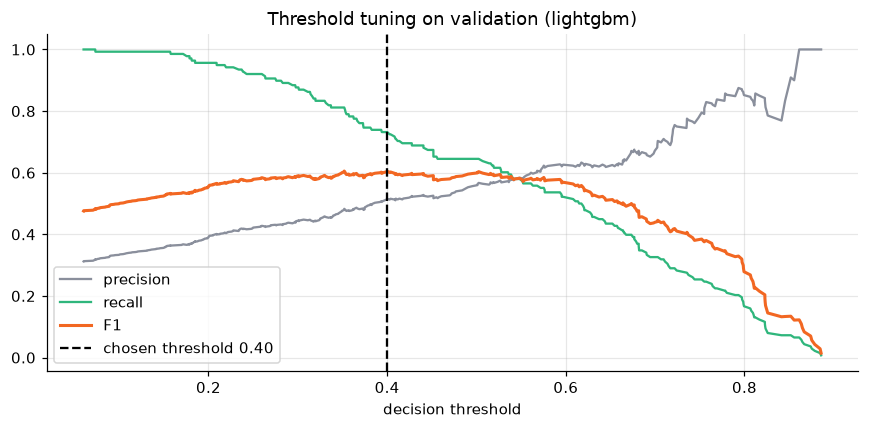

selected: lightgbm threshold: 0.4


In [19]:
best = val_table.drop("baseline_prior")["val_pr_auc"].idxmax()
best_model, threshold, _ = fitted[best]
pv = best_model.predict_proba(Xva)[:, 1]
prec, rec, thr = precision_recall_curve(yva, pv)
f1s = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, prec[:-1], label="precision", color=GREY)
ax.plot(thr, rec[:-1], label="recall", color=GREEN)
ax.plot(thr, f1s[:-1], label="F1", color=ORANGE, lw=2)
ax.axvline(threshold, ls="--", color="black", label=f"chosen threshold {threshold:.2f}")
ax.set_xlabel("decision threshold")
ax.set_title(f"Threshold tuning on validation ({best})")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "threshold.png", bbox_inches="tight")
plt.show()
print("selected:", best, "threshold:", threshold)

The default threshold of 0.5 is not the best for an imbalanced problem. I pick the threshold that maximises F1 on validation. A lower threshold catches more failures at the cost of more false alarms, which suits early warning: a false alarm only means a developer takes a second look.

## 9. Final evaluation on the test set

Each model is refitted on training plus validation with its tuned settings, then scored once on the untouched test period.

In [20]:
trval_X, trval_y = pd.concat([Xtr, Xva]), pd.concat([ytr, yva])
test_rows, test_proba = [], {}
for name, (m, t, _) in fitted.items():
    refit = clone(m).fit(trval_X, trval_y)
    test_proba[name] = refit.predict_proba(Xte)[:, 1]
    test_rows.append({"model": name, "threshold": t, **scores(yte, test_proba[name], t)})
    if name == best:
        final_model = refit
test_rows.append({"model": "baseline_prior", "threshold": 0.5, **scores(yte, np.full(len(yte), ytr.mean()), 0.5)})
test_table = pd.DataFrame(test_rows).set_index("model").round(3)
test_table

,threshold,roc_auc,pr_auc,f1,precision,recall
model,,,,,,
logistic_regression,0.37,0.667,0.485,0.491,0.375,0.714
random_forest,0.32,0.682,0.460,0.547,0.393,0.900
lightgbm,0.40,0.697,0.514,0.532,0.438,0.679
xgboost,0.45,0.692,0.480,0.508,0.453,0.579
baseline_prior,0.50,0.500,0.316,0.000,0.000,0.000


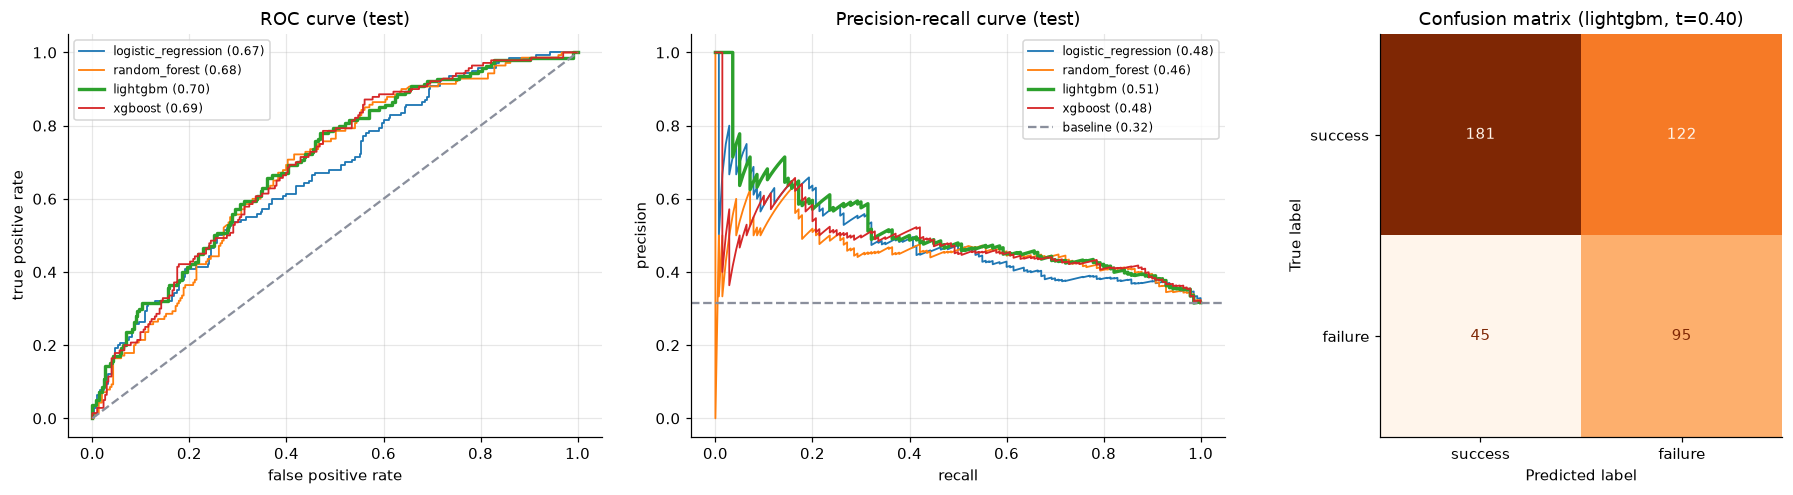

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(yte, p)
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(yte, p):.2f})", lw=2.2 if name == best else 1.2)
    pr, rc, _ = precision_recall_curve(yte, p)
    ax[1].plot(rc, pr, label=f"{name} ({average_precision_score(yte, p):.2f})", lw=2.2 if name == best else 1.2)
ax[0].plot([0, 1], [0, 1], "--", color=GREY)
ax[0].set(title="ROC curve (test)", xlabel="false positive rate", ylabel="true positive rate")
ax[1].axhline(yte.mean(), ls="--", color=GREY, label=f"baseline ({yte.mean():.2f})")
ax[1].set(title="Precision-recall curve (test)", xlabel="recall", ylabel="precision")
ax[0].legend(fontsize=8)
ax[1].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(yte, (test_proba[best] >= threshold).astype(int), ax=ax[2],
                                        display_labels=["success", "failure"], cmap="Oranges", colorbar=False)
ax[2].set_title(f"Confusion matrix ({best}, t={threshold:.2f})")
ax[2].grid(False)
plt.tight_layout()
plt.savefig(FIG / "test_curves.png", bbox_inches="tight")
plt.show()

In [22]:
pred = (test_proba[best] >= threshold).astype(int)
per_repo = test.assign(p=test_proba[best], pred=pred).groupby("repo").apply(
    lambda g: pd.Series({"runs": len(g), "failure_rate": g.failed.mean(),
                         "pr_auc": average_precision_score(g.failed, g.p) if g.failed.nunique() > 1 else np.nan,
                         "recall": recall_score(g.failed, g.pred, zero_division=0),
                         "precision": precision_score(g.failed, g.pred, zero_division=0)}))
per_repo.round(3)

,runs,failure_rate,pr_auc,recall,precision
repo,,,,,
ballerina-platform/module-ballerina-grpc,21.0,0.286,0.623,0.333,0.400
ballerina-platform/module-ballerina-http,68.0,0.382,0.643,0.923,0.421
ballerina-platform/module-ballerinax-kafka,7.0,0.714,0.876,0.600,1.000
wso2/carbon-apimgt,125.0,0.360,0.406,0.578,0.377
wso2/carbon-identity-framework,135.0,0.289,0.564,0.667,0.531
wso2/identity-apps,87.0,0.218,0.494,0.737,0.412


In [23]:
tp = int(((pred == 1) & (yte == 1)).sum()); fn = int(((pred == 0) & (yte == 1)).sum())
fp = int(((pred == 1) & (yte == 0)).sum()); tn = int(((pred == 0) & (yte == 0)).sum())
print(f"failures in test: {tp + fn}, caught: {tp} ({tp / (tp + fn):.0%}), missed: {fn}")
print(f"builds flagged: {tp + fp}, of which really failed: {tp / (tp + fp):.0%} (base rate {yte.mean():.0%})")

failures in test: 140, caught: 95 (68%), missed: 45
builds flagged: 217, of which really failed: 44% (base rate 32%)


**Interpreting the test result.** On the newest three weeks of builds, the selected model:
- ranks failures well above chance (ROC-AUC about 0.70),
- reaches a PR-AUC of about 0.51, against 0.32 for the baseline,
- catches about two thirds of the failing builds,
- is right about 44% of the time when it flags a build, against a 32% base rate.

This is a realistic level for the problem: the model only sees metadata, not the code or test logs, and many failures are caused by flaky tests or infrastructure problems that no metadata can predict. The model is useful as an **early-warning signal**, not as a replacement for running the build.

Performance differs by repository. It is best on the Ballerina HTTP module (PR-AUC 0.64) and `carbon-identity-framework` (0.56), and weakest on `carbon-apimgt` (0.41), whose failures depend less on the PR's or author's history. The kafka and grpc modules have only 7 and 21 test runs, so their numbers are not reliable.

## 10. Explainability

### 10.1 SHAP (global)
SHAP's `TreeExplainer` gives the exact contribution of each feature to each prediction, in log-odds.

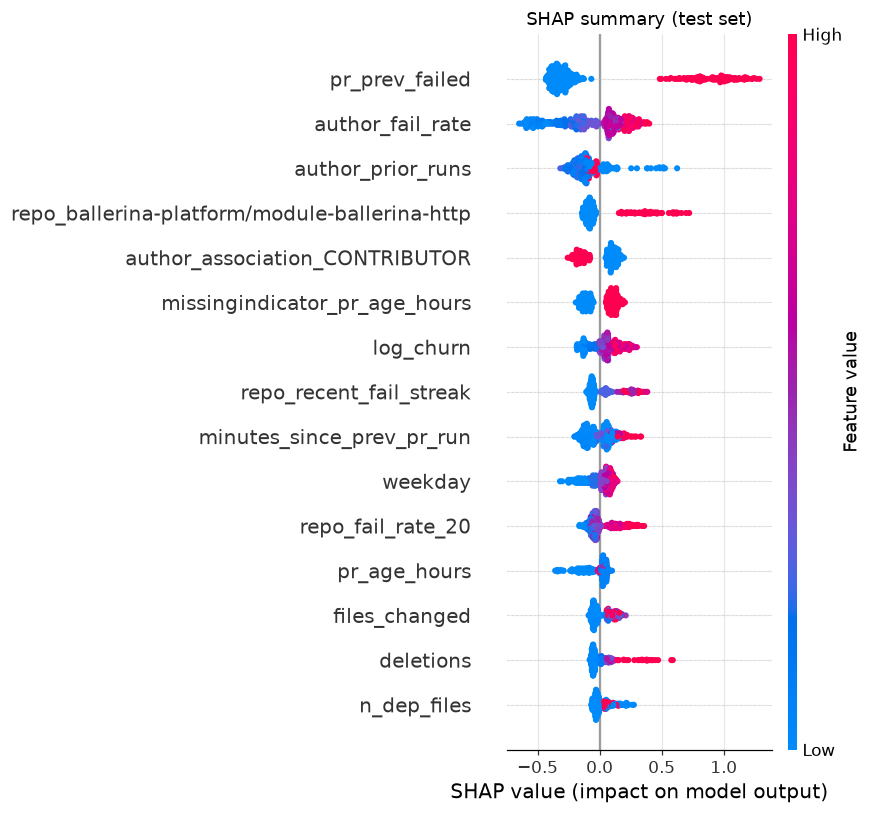

In [24]:
prep = final_model.named_steps["prep"]
clf = final_model.named_steps["model"]
names = list(prep.get_feature_names_out())
Xte_t = pd.DataFrame(prep.transform(Xte), columns=names, index=Xte.index)
explainer = shap.TreeExplainer(clf)
sv = explainer.shap_values(Xte_t)
sv = sv[1] if isinstance(sv, list) else np.asarray(sv)
base_value = float(np.atleast_1d(explainer.expected_value)[-1])

shap.summary_plot(sv, Xte_t, max_display=15, show=False)
plt.title("SHAP summary (test set)")
plt.tight_layout()
plt.savefig(FIG / "shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

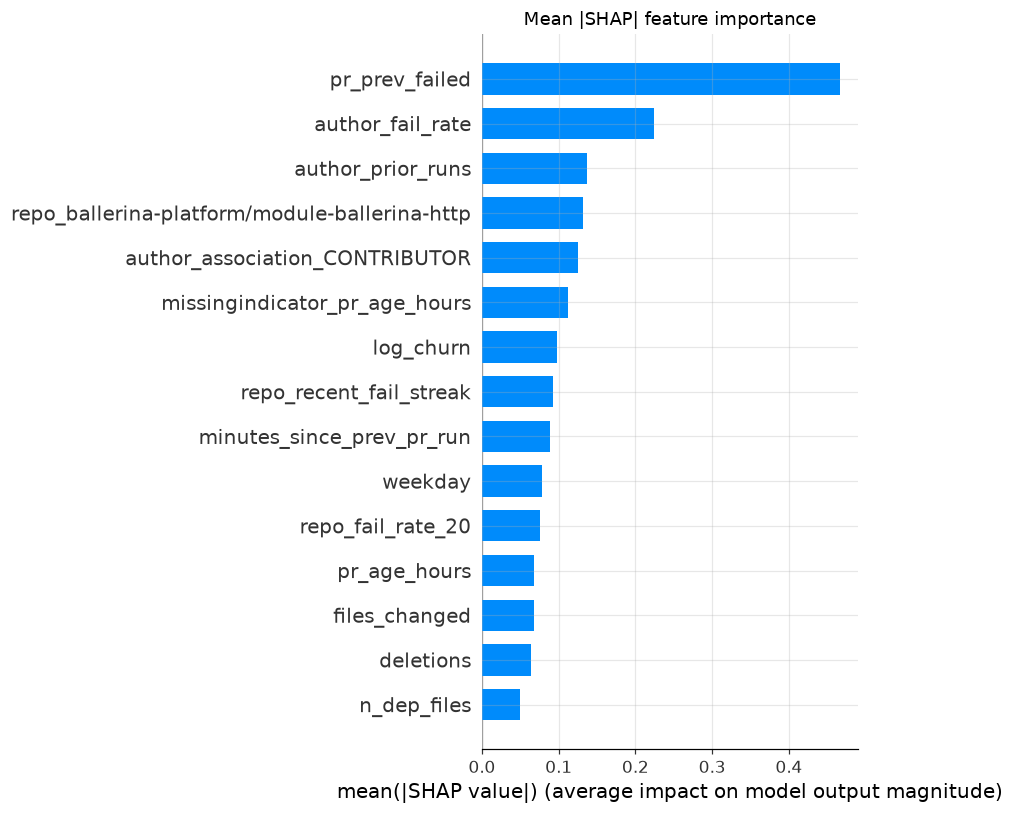

In [25]:
shap.summary_plot(sv, Xte_t, plot_type="bar", max_display=15, show=False)
plt.title("Mean |SHAP| feature importance")
plt.tight_layout()
plt.savefig(FIG / "shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

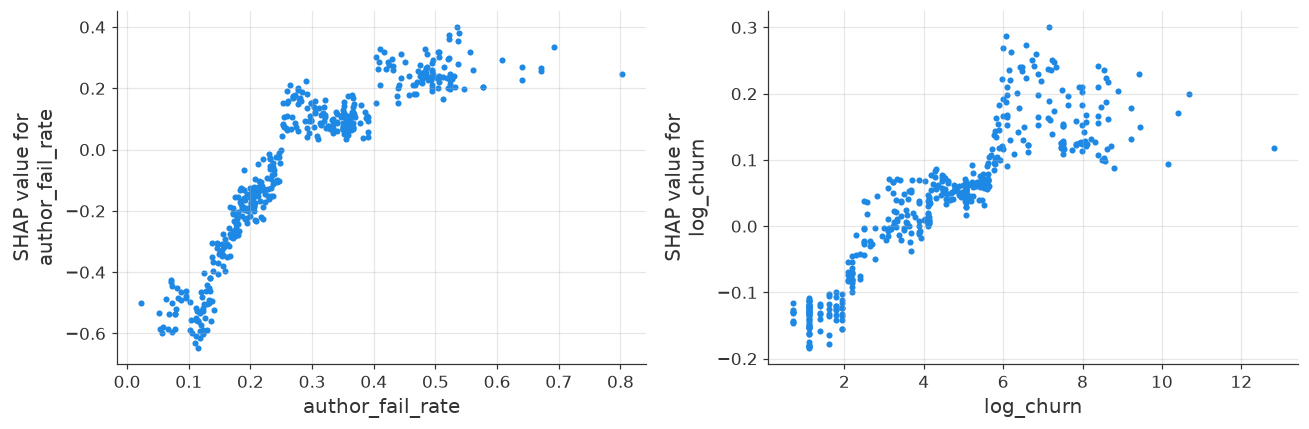

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
shap.dependence_plot("author_fail_rate", sv, Xte_t, interaction_index=None, ax=ax[0], show=False)
shap.dependence_plot("log_churn", sv, Xte_t, interaction_index=None, ax=ax[1], show=False)
plt.tight_layout()
plt.savefig(FIG / "shap_dependence.png", dpi=150, bbox_inches="tight")
plt.show()

What the model has learned:
1. **Last run on this PR failed** is by far the strongest driver. A failed PR tends to fail again on the next push.
2. **The author's track record.** Authors with higher past failure rates are riskier, while authors with many earlier runs, the regular contributors, are safer.
3. **Repository.** The Ballerina HTTP module has a higher base risk.
4. **Change size and history.** Larger changes and a repo already on a failure streak add risk. The dependence plot shows risk rising steadily with change size rather than jumping at one point.
5. **Missing PR details** slightly raise risk. These are mostly fork PRs from outside contributors.

These match how CI works in practice, which gives confidence that the model is not fitting noise.

### 10.2 SHAP (local) for one failed and one passed build

failed_run: predicted failure probability 0.87, actual failure


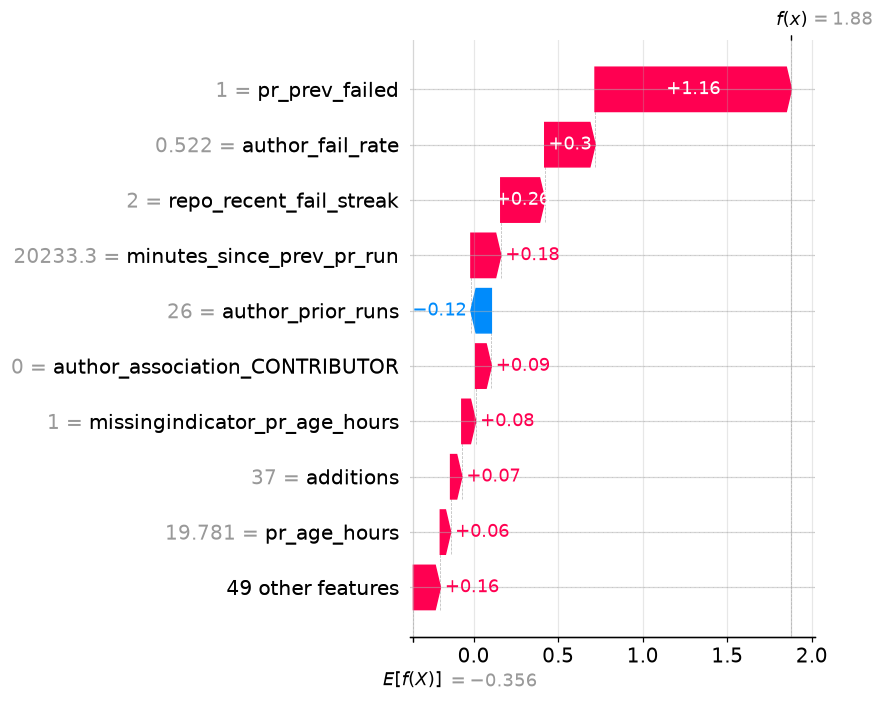

passed_run: predicted failure probability 0.06, actual success


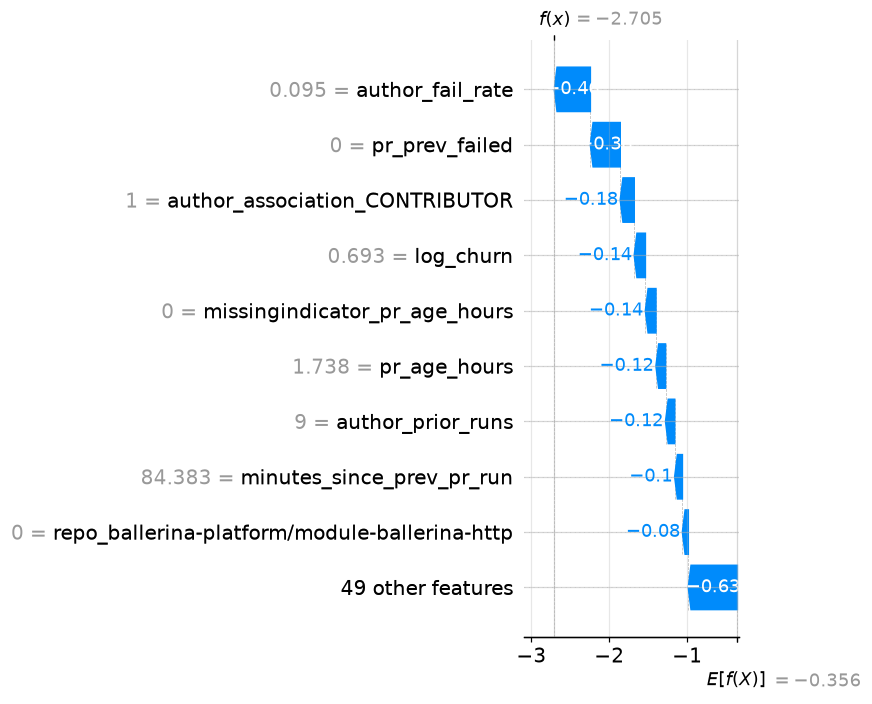

In [27]:
proba = final_model.predict_proba(Xte)[:, 1]
y = yte.to_numpy()
i_fail = int(np.argmax(np.where(y == 1, proba, -1)))
i_pass = int(np.argmin(np.where(y == 0, proba, 2)))
for label, i in (("failed_run", i_fail), ("passed_run", i_pass)):
    print(f"{label}: predicted failure probability {proba[i]:.2f}, actual {'failure' if y[i] else 'success'}")
    shap.plots.waterfall(shap.Explanation(sv[i], base_values=base_value, data=Xte_t.iloc[i].to_numpy(),
                                          feature_names=names), max_display=10, show=False)
    plt.tight_layout()
    plt.savefig(FIG / f"shap_waterfall_{label}.png", dpi=150, bbox_inches="tight")
    plt.show()

### 10.3 LIME as a second opinion
LIME fits a small linear model around one prediction. I explain the same failed build and compare its top features with SHAP.

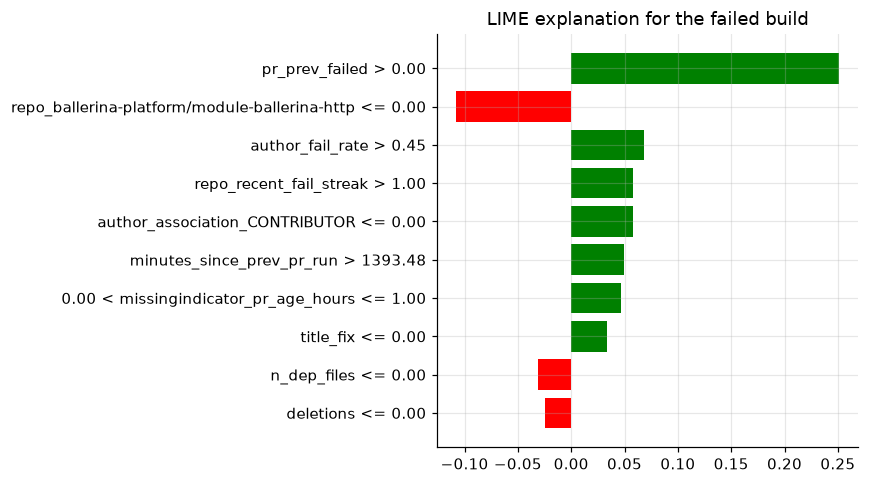

LIME local fit R²: 0.655
features in both top-10 lists: ['author_fail_rate', 'minutes_since_prev_pr_run', 'missingindicator_pr_age_hours', 'pr_age_hours', 'pr_prev_failed', 'repo_recent_fail_streak']


In [28]:
Xtr_t = prep.transform(trval_X)
lime_exp = LimeTabularExplainer(Xtr_t, feature_names=names, class_names=["success", "failure"],
                                discretize_continuous=True, random_state=SEED)
exp = lime_exp.explain_instance(Xte_t.iloc[i_fail].to_numpy(), clf.predict_proba, num_features=10)
fig = exp.as_pyplot_figure()
fig.set_size_inches(8, 4.5)
plt.title("LIME explanation for the failed build")
plt.tight_layout()
plt.savefig(FIG / "lime_failed_run.png", dpi=150, bbox_inches="tight")
plt.show()

lime_top = [n for n in names if any(n in rule for rule, _ in exp.as_list())][:10]
shap_top = list(pd.Series(np.abs(sv[i_fail]), index=names).sort_values(ascending=False).index[:10])
print("LIME local fit R²:", round(exp.score, 3))
print("features in both top-10 lists:", sorted(set(lime_top) & set(shap_top)))

LIME and SHAP agree on the main drivers of this prediction, mainly the PR's previous failure and the author's history. LIME's local linear fit is only approximate (see its R²) and changes a little with sampling, so I treat SHAP as the main explanation and LIME as a cross-check.

## 11. Error analysis

In [29]:
errors = test.assign(p=proba, pred=pred)
errors["type"] = np.select([(errors.pred == 1) & (errors.failed == 1), (errors.pred == 0) & (errors.failed == 1),
                            (errors.pred == 1) & (errors.failed == 0)], ["caught failure", "missed failure", "false alarm"],
                           "correct pass")
cols = ["pr_prev_failed", "pr_prior_runs", "author_fail_rate", "author_prior_runs", "log_churn", "files_changed", "is_bot"]
errors.groupby("type")[cols].mean().round(2)

,pr_prev_failed,pr_prior_runs,author_fail_rate,author_prior_runs,log_churn,files_changed,is_bot
type,,,,,,,
caught failure,0.51,17.93,0.36,54.63,5.45,27.80,0.11
correct pass,0.01,5.40,0.24,33.36,3.64,8.89,0.07
false alarm,0.50,17.58,0.33,56.80,5.25,41.70,0.10
missed failure,0.02,19.78,0.23,26.49,4.19,13.16,0.00


- **Missed failures** almost always come right after a passing run on the same PR (only 2% follow a failure), from authors with low failure rates and smaller changes. Nothing in the metadata points to trouble, so many are probably flaky tests or infrastructure failures.
- **False alarms** look almost the same as caught failures: half follow a failed run, and they are large changes. The difference is that the developer's new push actually fixed the problem, which the model can't see.

Both point to the same next step: features from inside the build, such as which tests failed last time and which modules changed, would help more than further tuning.

## 12. Conclusion

| | |
|---|---|
| Data | 2,948 real GitHub Actions PR builds from 6 WSO2 and Ballerina repositories, collected through the API |
| Approach | Leakage-free history features, time-ordered split, 4 tuned models plus baseline, threshold tuned on validation |
| Best model | LightGBM: test ROC-AUC about 0.70, PR-AUC about 0.51 (baseline 0.32), recall about 0.68 |
| Main drivers | the PR's previous run, the author's track record, the repository, change size, the repo's recent streak |

**Recommendations for a DevOps team**
- Flag PR builds after a failed run and show the developer the likely cause before they wait for the full pipeline.
- Give first-time and outside contributors faster feedback, such as lint and unit tests first.
- Track the repo failure streak as a health metric: a streak raises the risk for everyone's builds.

**Limitations**
- Public repos only; WSO2's history covers about 4 months because of the run cap.
- Failure labels include flaky tests and runner problems, which no metadata can predict.
- Commit statistics describe the triggering commit, not the whole PR.
- New authors and new PRs have little history (cold start).

**Future work:** add test-level history from build logs, collect a longer period, and retrain monthly while watching for drift.

In [30]:
Path("models").mkdir(exist_ok=True)
joblib.dump({"model": final_model, "threshold": threshold, "features": FEATURES, "name": best}, "models/model.joblib")
print("saved models/model.joblib –", best, "threshold", threshold)

saved models/model.joblib – lightgbm threshold 0.4


The saved model powers the Streamlit front end (`streamlit run app/app.py`). `python -m src.train` rebuilds the same model from the command line, using the same features, split, search space and seed.